# California Proposition 99

Cigarette consumption, 1970–2000; first affected year 1989. Outcome: cigarette packs per capita.

The SDID reference is −15.6038278727 packs per person. This is the no-covariate example in Arkhangelsky et al. (2021), [AER](https://doi.org/10.1257/aer.20190159), using the tobacco-control setting of Abadie, Diamond and Hainmueller (2010), [JASA](https://doi.org/10.1198/jasa.2009.ap08746). The latter's covariate-based SCM specification is **not** reproduced by the outcome-only SCM row below.

Run from a checkout installed using `requirements-replication.txt` and `pip install -e .`. This notebook downloads immutable public data using **requests**; an internet connection is required. See [the replication guide](../docs/replication.md) for provenance and scope.

In [1]:
%matplotlib inline
import hashlib
from io import BytesIO
from importlib.metadata import version

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from pysynth import (SyntheticControl, SCUL, IndividualSC, TwoStageIndividualSC, SyntheticDID,
                     DifferenceInDifferences, PySyncon, SCM, compare)
from pysynth.datasets import DATASETS
from pysynth.replication import replicate, check_replication

pd.Series({p: version(p) for p in ['pysynth-control', 'numpy', 'scipy', 'pandas', 'pysyncon', 'SyntheticControlMethods']}, name='version')

pysynth-control             0.1.0
numpy                       2.0.2
scipy                      1.13.1
pandas                      2.3.3
pysyncon                    1.7.0
SyntheticControlMethods    1.1.17
Name: version, dtype: object

## Download and verify the academic data

The URL names an immutable upstream commit. SHA256 verification fails visibly if the bytes differ. No manual download or bundled dataset is required.

In [2]:
name = 'california'
spec = DATASETS[name]
response = requests.get(spec.url, timeout=30)
response.raise_for_status()
assert hashlib.sha256(response.content).hexdigest() == spec.sha256
data = pd.read_csv(BytesIO(response.content), sep=spec.separator)
panel = spec.panel(data)
print(spec.citation)
print(spec.url)
print(f'{panel.n_control} donors; {panel.n_pre} pre-periods; {panel.n_post} post-periods')
data.head()

Abadie, Diamond & Hainmueller (2010), doi:10.1198/jasa.2009.ap08746; Arkhangelsky et al. (2021), doi:10.1257/aer.20190159
https://raw.githubusercontent.com/synth-inference/synthdid/70c1ce3eac58e28c30b67435ca377bb48baa9b8a/data/california_prop99.csv
38 donors; 19 pre-periods; 12 post-periods


,State,Year,PacksPerCapita,treated
0,Alabama,1970,89.800003,0
1,Arkansas,1970,100.300003,0
2,Colorado,1970,124.800003,0
3,Connecticut,1970,120.000000,0
4,Delaware,1970,155.000000,0


## Reference specification and numerical check

This cell uses the historical specification described above. Its assertion is separate from the new-method comparison. See `pysynth.replication.replicate` for the full predictor windows and optimization settings.

/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/replication.py:24: RuntimeWarning: SDID reached max_iter before the objective-decrease stopping rule
  return SyntheticDID().fit(panel)


source                R synthdid reference ATT (paper reports -15.6)
estimate                                                  -15.603828
reference                                                 -15.603828
absolute_tolerance                                          0.000001
Name: Replication check, dtype: object

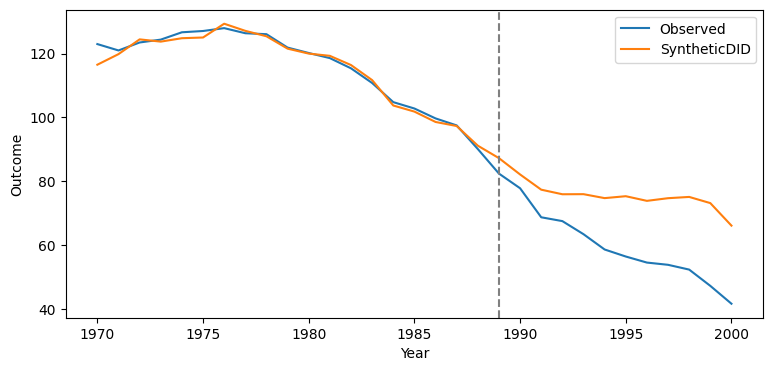

In [3]:
reference = replicate(name, data)
report = check_replication(name, reference)
display(pd.Series(report, name='Replication check'))
reference.plot()
plt.show()

## Compare all applicable methods

All rows use the same outcome panel, donor eligibility and intervention date. Native SCM assigns equal importance to outcome periods; the pysyncon SCM adapter standardizes predictor rows. Penalized and robust SCM use explicit illustrative tuning values below. The SyntheticControlMethods rows use at most ten evenly spaced pre-outcome lag predictors plus its outcome mean; this keeps the nested optimization practical for quarterly panels. SCUL selects its penalty by rolling validation entirely within the pre-period, using a shared pretreatment penalty grid.

Vanilla Individual Synthetic Control (ISC) fits over the full eligible donor pool. Two-Stage Individual Synthetic Control (2SISC) first selects up to ten nearest donors by pretreatment Euclidean distance, then fits convex weights within that group. Both are shown separately. With one aggregate treated case, default outcome features and no resampling, vanilla ISC coincides with Outcome SCM; that agreement is expected. These applications do not reproduce the Vagni–Breen survey study. SDID uses donor post-period outcomes to learn time weights, and robust SCM denoises donors over the full panel; neither uses treated post outcomes to estimate weights. The newer methods' rows are **new applications**, not estimates published in their development papers.

Upstream convergence warnings remain visible. No method is silently dropped if fitting fails.

In [4]:
models = {
    'Outcome SCM': SyntheticControl(),
    'SCUL': SCUL(initial_window=max(3, panel.n_pre // 2), horizon=1),
    'ISC (full donor pool)': IndividualSC(),
    '2SISC (nearest 10)': TwoStageIndividualSC(n_neighbors=10),
    'Synthetic DID': SyntheticDID(),
    'DID': DifferenceInDifferences(),
    'pysyncon SCM': PySyncon('synth'),
    'Augmented SCM': PySyncon('augsynth'),
    'Penalized SCM (0.01)': PySyncon('pensynth', options={'lambda_': 0.01}),
    'Robust SCM (rank 3, ridge 0.1)': PySyncon('robust', options={'lambda_': 0.1, 'sv_count': 3}),
    'SyntheticControlMethods SCM': SCM('synth', n_lags=10),
    'Differenced SCM': SCM('diffsynth', n_lags=10),
}
results = {label: model.fit(panel) for label, model in models.items()}
comparison = compare(results)
comparison.round(4)

/tmp/ipykernel_3586983/4148541051.py:15: RuntimeWarning: SDID reached max_iter before the objective-decrease stopping rule
  results = {label: model.fit(panel) for label, model in models.items()}


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           11     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  6.40026D+01    |proj g|=  9.09091D-01



At iterate    3    f=  5.89555D+01    |proj g|=  9.31964D-01

At iterate    6    f=  5.54762D+01    |proj g|=  8.74908D-01



At iterate    9    f=  5.28935D+01    |proj g|=  9.83507D-01

At iterate   12    f=  5.23476D+01    |proj g|=  9.99072D-01



At iterate   15    f=  5.23419D+01    |proj g|=  9.65133D-01

At iterate   18    f=  5.22992D+01    |proj g|=  9.99329D-01



At iterate   21    f=  5.22420D+01    |proj g|=  9.94057D-01


... (13 outputs left out)


At iterate   15    f=  3.72119D+01    |proj g|=  9.99137D-01



           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
   11     16     49     31     0     2   9.991D-01   3.721D+01
  F =   37.211929669063089     

CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH             



   evaluations in the last line search.  Termination
   may possibly be caused by a bad search direction.


,att,pre_rmse,donors_used,weight_sum
model,,,,
Outcome SCM,-19.5141,1.6564,6,1.0000
SCUL,-16.7755,0.3516,13,0.9466
ISC (full donor pool),-19.5141,1.6564,6,1.0000
2SISC (nearest 10),-22.6480,3.6707,4,1.0000
Synthetic DID,-15.6038,1.8057,28,1.0000
DID,-27.3491,7.1572,38,1.0000
pysyncon SCM,-19.7544,1.6956,6,1.0000
Augmented SCM,-15.9525,0.7337,38,1.0000
Penalized SCM (0.01),-22.2775,3.0084,5,1.0000


## Estimated effect paths

Differences across estimates reflect different restrictions, extrapolation, regularization and level adjustments. Pre-period RMSE measures fit; it does not validate the identifying assumptions or rank causal credibility.

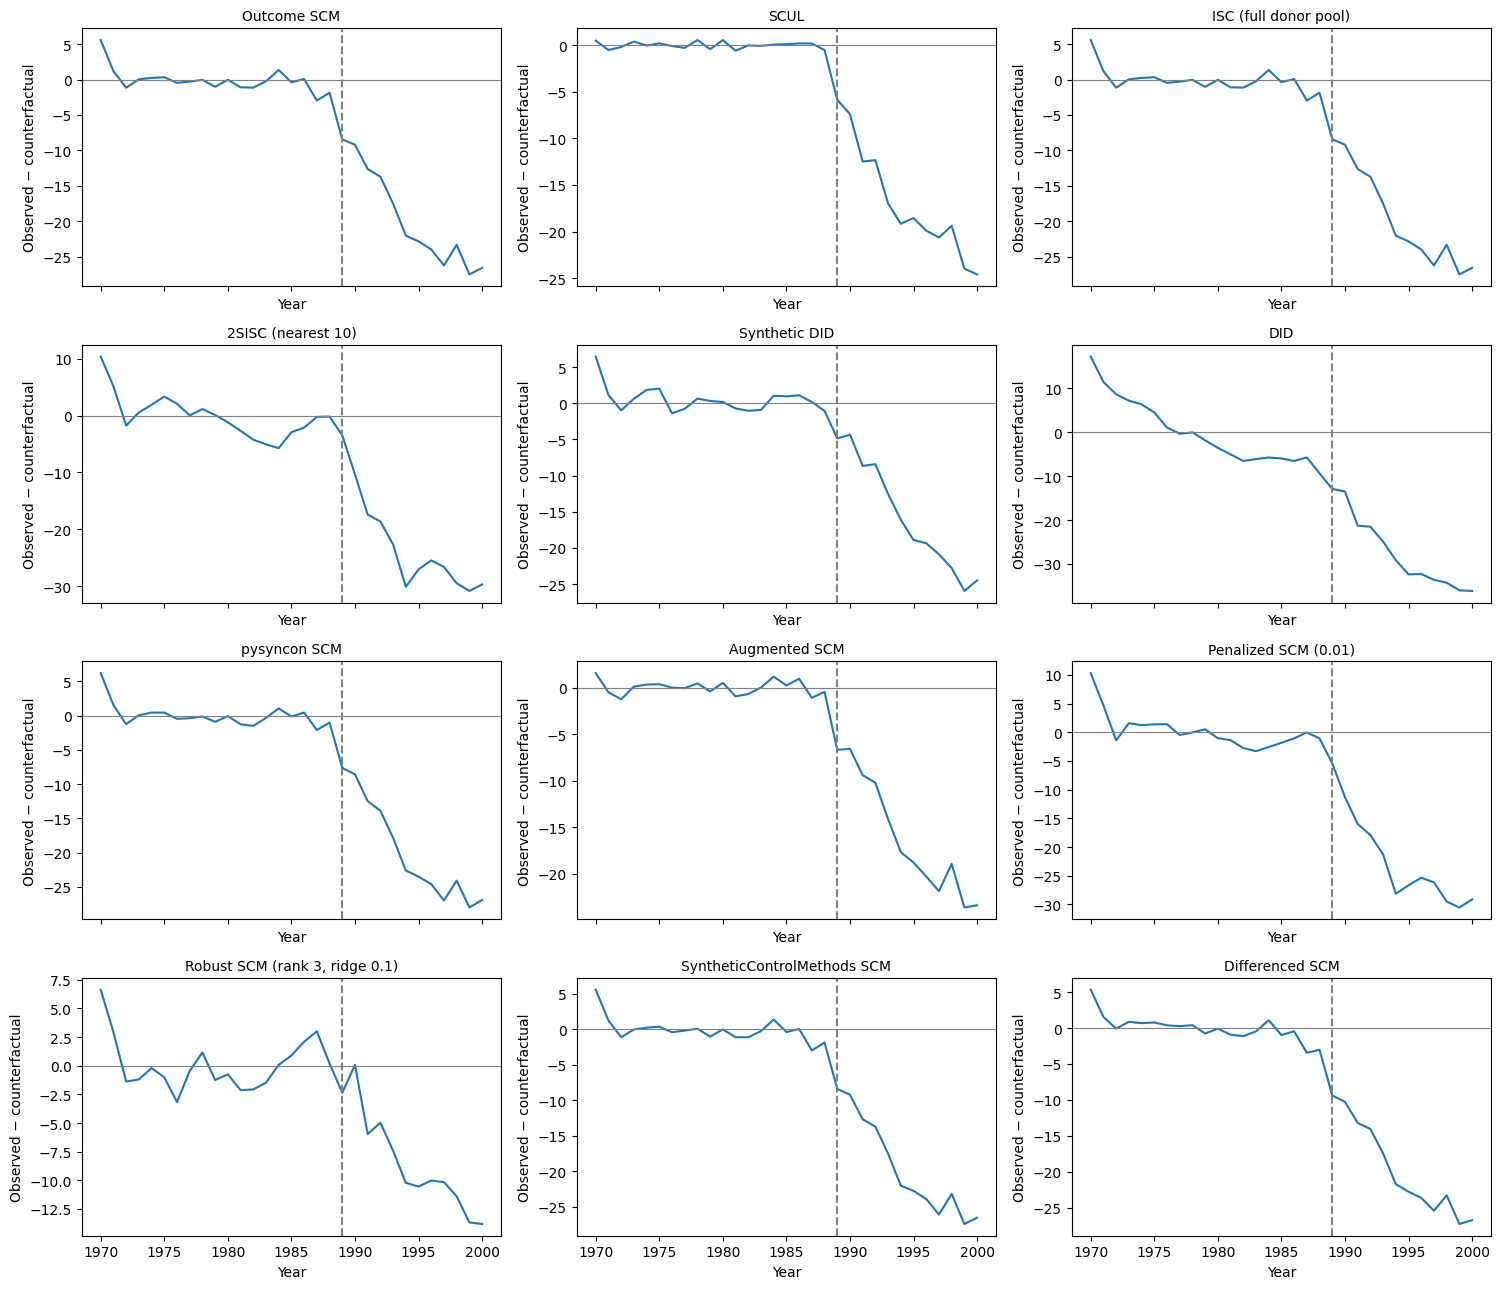

In [5]:
fig, axes = plt.subplots(4, 3, figsize=(15, 13), sharex=True)
for ax, (label, result) in zip(axes.flat, results.items()):
    result.plot(ax=ax, effects=True)
    ax.set_title(label, fontsize=10)
    ax.get_legend().remove()
for ax in list(axes.flat)[len(results):]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()

In [6]:
weights = pd.concat({label: fit.weights for label, fit in results.items()}, axis=1)
weights.loc[weights.abs().max(axis=1).sort_values(ascending=False).index].head(15).round(4)

,Outcome SCM,SCUL,ISC (full donor pool),2SISC (nearest 10),Synthetic DID,DID,pysyncon SCM,Augmented SCM,Penalized SCM (0.01),"Robust SCM (rank 3, ridge 0.1)",SyntheticControlMethods SCM,Differenced SCM
Utah,0.3939,0.2382,0.3939,0.0000,0.0415,0.0263,0.3845,0.3702,0.0000,0.0307,0.3929,0.3451
Montana,0.2319,0.1164,0.2319,0.2663,0.0451,0.0263,0.2721,0.2484,0.3753,0.0211,0.2223,0.2389
Idaho,0.0000,0.0797,0.0000,0.3551,0.0315,0.0263,0.0000,-0.0191,0.2881,0.0404,0.0000,0.0000
Tennessee,0.0000,-0.2738,0.0000,0.0000,0.0000,0.0263,0.0000,-0.0414,0.0000,-0.0536,0.0000,0.0000
Colorado,0.0148,0.0408,0.0148,0.2552,0.0575,0.0263,0.0290,0.0329,0.0000,0.0635,0.0264,0.0000
Nevada,0.2049,0.1512,0.2049,0.0000,0.1245,0.0263,0.1865,0.2020,0.0817,0.1194,0.2062,0.2192
Nebraska,0.0000,0.1872,0.0000,0.0000,0.0479,0.0263,0.0000,0.0267,0.0000,0.0171,0.0000,0.0000
Connecticut,0.1091,0.1573,0.1091,0.1234,0.0783,0.0263,0.0794,0.1512,0.1010,0.0590,0.1086,0.1567
New Mexico,0.0000,0.0519,0.0000,0.0000,0.0406,0.0263,0.0000,-0.0004,0.1539,0.0510,0.0000,0.0000
Illinois,0.0000,0.1500,0.0000,0.0000,0.0534,0.0263,0.0000,0.0502,0.0000,0.0836,0.0000,0.0000


## Interpretation and reproducibility

The ATT is the average observed-minus-counterfactual gap in the post-period, in the stated outcome units. Negative effects mean an outcome below its estimated untreated path. No automatic confidence interval is reported: serial dependence, donor eligibility, spillovers and assignment assumptions need a defensible inferential design.

`pysynth.placebo_test` offers in-space RMSPE-ratio diagnostics and a rank p-value under exchangeability assumptions. It is not the synthdid package's placebo variance estimator. SCUL's original scanner-data empirical study and the costofcare/ISC survey study are not reproduced here: their original data and full research designs differ from these public canonical panels.

The downloaded bytes and software versions are recorded above. Re-run the notebook from a fresh kernel to reproduce both the reference check and the comparison.